# Ten pilots with varied Transformers, PPO loss weights and rewards

Train **10 independent pilots** against the **simple JSBSim opponent**, using the
current `change_trajectory`/`launch` catalogue. This notebook follows notebook 06:
80 epochs per pilot, 50 training scenarios, 50 shared validation scenarios,
separate checkpoints and MLflow runs, comparison plots and selected-pilot replays.

Each pilot draws a Transformer width from **56, 64, 72**, and a layer count from
**1, 2, 3**, keeping four attention heads. The value-loss coefficient varies uniformly
from **0.45 to 0.55** and the entropy coefficient from **0.009 to 0.011**. The PPO
policy-loss multiplier stays at one. Notebook 06's existing evade/pursue/eliminate
reward preferences and shared guidance terms are retained.

A separate variation seed makes the architectural/loss draws reproducible. The
full roster is displayed before training and recorded in `pilots.json` before any
pilot runs. Exact effective settings are also saved in each pilot's `config.json`,
`manifest.json` and MLflow parameters. `variant_roster.csv` is exported when training
finishes or raises an exception. New output folders preserve previous experiments.

Architecture, loss weights and rewards vary together: this is a population-diversity
experiment. Common scenario seeds match the flight conditions, but networks with
different shapes do not have identical initial weights. Common benchmark scores
compare outcomes; raw PPO losses or differently weighted own rewards do not isolate
which variation caused a difference.


## Setup

Install dependencies from the repository root, then restart the kernel:

```bash
python -m pip install -e '.[ml,video]'
```

For GPU training, install a CUDA-enabled PyTorch build in the selected kernel's
environment and restart the kernel. See `docs/multi_pilot_training.md` for setup.
Policy inference and PPO updates use CUDA when available; JSBSim and opponent
control run in separate CPU processes so Python control code can use multiple cores.
Processes are reused across epochs. `BVR_PILOT_DEVICE` can explicitly select a device.
After a code update, restart the kernel and run from the top; confirm the configuration
prints `simulator_executor: process`. The first flight batch includes worker startup.
`BVR_PILOT_EXECUTOR=thread` restores the previous collector for a timing comparison.

For an installation check, set `BVR_PILOT_EPOCHS=1`, `BVR_PILOT_EPISODE_SECONDS=1`,
`BVR_PILOT_SCENARIOS=3`, `BVR_PILOT_EVALUATION_SCENARIOS=3`, and
`BVR_PILOT_UPDATE_EPOCHS=1` before starting Jupyter. Set `BVR_PILOT_COUNT` to any positive
number (default 10), or define an explicit `PILOTS` list below.
To leave capacity for VS Code and other work, `BVR_PILOT_WORKERS` defaults to 80%
of the logical CPU count, rounded down with a minimum of one worker. `BVR_PILOT_TORCH_THREADS`
caps PyTorch CPU operations at up to 8 threads by default. Both are configurable
before setup; explicit environment values override the defaults. These limits
reduce concurrency but do not reserve specific cores or guarantee a CPU percentage.
CUDA graphs accelerate full PPO minibatches by replaying their GPU operations together.
The 50 update passes, batch size of 64, optimizer and shared validation follow notebook 06.
CPU execution and partial minibatches use the ordinary update path. Set
`BVR_PILOT_CUDA_GRAPHS=0` before setup to disable capture for comparisons.
Notebook 04 retains its ordinary update path. Restart the kernel after code changes.

The progress bar identifies flight collection, PPO updates, validation, and replay saving.
CPU load falls during GPU updates. Compare `rollout_seconds`, `update_seconds`, and
`checkpoint_seconds` in the saved metrics. `cuda_graph_updates: 1` confirms graph use;
`simulator_effective_cores` measures CPU use during simulator steps.
For a quick real-backend check of all ten variants, set the following environment
variables **before running the setup cell**: `BVR_PILOT_EPOCHS=1`,
`BVR_PILOT_EPISODE_SECONDS=1`, `BVR_PILOT_SCENARIOS=3`,
`BVR_PILOT_EVALUATION_SCENARIOS=3`, `BVR_PILOT_UPDATE_EPOCHS=1`,
`BVR_PILOT_WORKERS=1`, `BVR_PILOT_TORCH_THREADS=1`, and `BVR_PILOT_DEVICE=cpu`.
Leave `BVR_PILOT_COUNT` unset to check all ten. This verifies execution, not learning
quality. Change the editable choices/ranges below for a new experiment.


In [10]:
import json
import os
from dataclasses import replace
from datetime import datetime, timezone
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Leave CPU capacity for the editor and other applications.
DEFAULT_SIMULATOR_WORKERS = max(1, ((os.cpu_count() or 1) * 80) // 100)
TORCH_THREADS = int(os.getenv(
    "BVR_PILOT_TORCH_THREADS", str(min(8, DEFAULT_SIMULATOR_WORKERS))
))
if TORCH_THREADS < 1:
    raise ValueError("BVR_PILOT_TORCH_THREADS must be positive")
torch.set_num_threads(TORCH_THREADS)

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "bvr_behavior_prediction").exists():
    REPO_ROOT = REPO_ROOT.parent
for source_root in (REPO_ROOT, REPO_ROOT / "bvr_sim_source"):
    if str(source_root) not in sys.path:
        sys.path.insert(0, str(source_root))

from bvr_sim.agents.skill_manager import SkillManager
from bvr_behavior_prediction.rl.bvr_jsbsim_backend import BVRJSBSimBackend
from bvr_behavior_prediction.rl.config import PilotTrainingConfig
from bvr_behavior_prediction.rl.environment import BluePilotEnvironment
from bvr_behavior_prediction.rl.multi_pilot import PilotSpec, train_pilots, load_trained_pilot
from bvr_behavior_prediction.rl.dogfight_reward import (
    dogfight_population_weights, hybrid_dogfight_reward_definition,
)
from bvr_behavior_prediction.rl.trainer import PPOTrainer
from bvr_behavior_prediction.rl.population_variations import SAMPLER_VERSION, sample_training_variations

SEED = int(os.getenv("BVR_PILOT_SEED", "7"))
# Matched scenario seeds; different shapes do not share identical weights.
VARIATION_SEED = int(os.getenv("BVR_PILOT_VARIATION_SEED", "42"))
TRANSFORMER_HEADS = (4, 8)
SEED_STRIDE = int(os.getenv("BVR_PILOT_SEED_STRIDE", "0"))
evaluation_seed_value = os.getenv("BVR_PILOT_EVALUATION_SEED")
EVALUATION_SEED = int(evaluation_seed_value) if evaluation_seed_value else None
EPOCHS = int(os.getenv("BVR_PILOT_EPOCHS", "200"))
EPISODE_SECONDS = float(os.getenv("BVR_PILOT_EPISODE_SECONDS", "120"))
PILOT_COUNT = int(os.getenv("BVR_PILOT_COUNT", "10"))
if PILOT_COUNT < 1:
    raise ValueError("BVR_PILOT_COUNT must be positive")
BATCH_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = Path(os.getenv(
    "BVR_PILOT_OUTPUT", REPO_ROOT / "artifacts/rl_pilot_simplified/varied_transformers" / BATCH_ID
)).resolve()
DEVICE = os.getenv("BVR_PILOT_DEVICE", "cuda" if torch.cuda.is_available() else "cpu")
print({"device": DEVICE, "pilot_count": PILOT_COUNT, "epochs_per_pilot": EPOCHS,
       "torch_version": torch.__version__, "cuda_available": torch.cuda.is_available(),
       "torch_threads": torch.get_num_threads(), "output": str(OUTPUT_DIR)})
SKILL_CATALOGUE = SkillManager().get_catalogue()
print({"skill_catalogue_version": SKILL_CATALOGUE["version"],
       "skills": [skill["name"] for skill in SKILL_CATALOGUE["skills"]]})


{'device': 'cuda', 'pilot_count': 10, 'epochs_per_pilot': 200, 'torch_version': '2.14.1+cu130', 'cuda_available': True, 'torch_threads': 8, 'output': 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\rl_pilot_simplified\\varied_transformers\\20261113T195250_365660Z'}
{'skill_catalogue_version': '4.0.0', 'skills': ['change_trajectory', 'launch']}


## BVR Sim backend with JSBSim flight dynamics

Each independent pilot controls one F-16 through the simplified two-skill `SkillManager` catalogue.
The opponent uses BVR Sim's existing simple baseline. The adapter translates tactical
skills into flight controls and records ACMI telemetry. Logs are isolated by pilot.

Each policy frame now has **91 features**: the original 47 compact features,
four nearest live hostile missiles targeting the controlled aircraft (10 features
each), and four energy features. Each missile slot contains presence, relative
North/West/Up position and velocity, range, signed closing speed, and seeker-active
status. Slots are sorted by range with UID tie-breaking; absent slots are zero.
Inputs use simulator truth, consistent with the compact enemy state, rather than
radar/MWS detection gating. The 20-frame history and 0.1-second sampling remain.
See `docs/varied_transformer_pilots.md` for indices and normalization.

Train fresh pilots: earlier 51-feature checkpoints require the legacy backend
(`include_hostile_missiles=False`) and cannot be loaded into these 91-input models.

In [11]:
BASE_OBSERVATION_SIZE = BVRJSBSimBackend.HOSTILE_MISSILE_OBSERVATION_SIZE
ENERGY_FEATURES = 4
OBSERVATION_SIZE = BASE_OBSERVATION_SIZE + ENERGY_FEATURES


def make_environment_factory(run_config):
    def bvr_jsbsim_backend_factory(scenario_dict, recording_path=None):
        return BVRJSBSimBackend(
            scenario_dict,
            recording_path=recording_path,
            log_dir=run_config.output_dir / "simulator_logs",
            include_hostile_missiles=True,
        )

    def make_environment(scenario, recording_path=None):
        return BluePilotEnvironment(
            bvr_jsbsim_backend_factory,
            scenario,
            planning_horizon_s=run_config.planning_horizon_s,
            episode_duration_s=run_config.episode_duration_s,
            history_duration_s=run_config.history_duration_s,
            sample_interval_s=run_config.sample_interval_s,
            recording_path=recording_path,
        )

    return make_environment

## Configure style priorities and shared combat guidance

Each pilot optimizes evade, pursue, and eliminate with different **relative** weights.
Weights sum to one; increasing one priority reduces the others.
`dogfight_population_weights(PILOT_COUNT)` spreads any positive number of pilots across
the preference triangle. Its default minimum weight of 0.1 keeps every objective relevant.
Pilot IDs are identifiers, not claims about learned aggression or defensive ability.

- **Evade:** defeat unique incoming missiles while minimizing time under active threat.
  Missile rewards are capped per flight so repeated threats cannot pay indefinitely.
- **Pursue:** improve the best engagement position reached during the flight. Closeness
  stops increasing the score inside the nominal 30 km engagement range; alignment can
  still improve. Returning to a previously reached position gives no extra reward.
- **Eliminate:** receive one weighted reward for a confirmed missile elimination.

Every pilot also shares a **+100 confirmed-elimination reward** and **-150 aircraft-loss
penalty**. Total elimination reward is therefore 125 to 300 for the default roster.
These give all pilots a reason to finish the engagement while allowing different priorities.

Small shared learning bonuses help every pilot learn the combat mechanics:

| Guidance | Maximum reward per flight |
| --- | --- |
| First target lock | +2, paid once |
| First launch with a lock | +8, paid once |
| Maintain lock while a live friendly missile's own seeker is inactive | +5, spread over at most 20 seconds |

All guidance together is capped at **15**. Repeated lock acquisition and repeated firing
cannot multiply those bonuses. Support credit ends when the lock is lost, the missile's
seeker activates, or the missile or target dies. These are bounded heuristic bonuses;
they are not a guarantee of optimal behaviour. Altitude and selecting a named skill
carry no separate bonuses. The simplified two-skill catalogue and simple opponent remain.

The common comparison benchmark disables the three guidance bonuses and scores outcomes
and style objectives with equal weights. Each pilot selects checkpoints using its own
training objective. Notebook **04 keeps its original `CombatReward`**, including its
original lock/launch/evasion/outcome weights; both recipes remain available.

The default uses the **same seed** for each fresh model and training scenario set.
This matches scenario conditions; different network shapes have different initial
weights, and the combined variations do not isolate reward effects. Use `BVR_PILOT_SEED_STRIDE=1000` for different
seeds per pilot, or repeat the roster with another `BVR_PILOT_SEED` to assess variability.
All pilots share a separate validation set for checkpoint selection. Reserve fresh
scenarios and opponents for final tests. Inspect outcomes and replays before assigning styles.

Edit `STYLE_WEIGHTS`, `REWARD_SETTINGS`, or supply your own `RewardDefinition` factories.
See `docs/multi_pilot_training.md` for the formula and alternative recipes.
### Editable architecture and PPO variation ranges

Widths are multiples of four so all draws have valid attention heads. Width changes
are ±12.5% around 64; layer counts differ by at most one from 2. Loss coefficients
vary by ±10% around notebook 06's defaults (0.5 value, 0.01 entropy). All numeric
values below are recorded without rounding. The reward roster remains generated
by `dogfight_population_weights`, exactly as in notebook 06.


In [12]:
STYLE_WEIGHTS = dogfight_population_weights(PILOT_COUNT)
REWARD_SETTINGS = {
    "episode_duration_s": EPISODE_SECONDS,
    "evasion_cap": 4,
    "pursuit_range_m": 30_000.0,
    "loss_penalty": 0.6,
    "reward_scale": 250.0,
    "elimination_bonus": 100.0,
    "lock_bonus": 2.0,
    "launch_bonus": 8.0,
    "dumb_launch_penalty": -2.0,
    "support_bonus": 5.0,
    "support_budget_s": 20.0,
}


def make_reward_definition(pilot_index):
    return hybrid_dogfight_reward_definition(
        f"hybrid_objective_{pilot_index + 1:03d}",
        weights=STYLE_WEIGHTS[pilot_index], **REWARD_SETTINGS,
    )


WIDTH_CHOICES = (56, 64, 72, 96)
LAYER_CHOICES = (1, 2, 3)
VALUE_COEFFICIENT_RANGE = (0.45, 0.55)
ENTROPY_COEFFICIENT_RANGE = (0.009, 0.011)
TRAINING_VARIATIONS = sample_training_variations(
    PILOT_COUNT, seed=VARIATION_SEED, widths=WIDTH_CHOICES, layers=LAYER_CHOICES,
    transformer_heads=TRANSFORMER_HEADS,
    value_coefficient_range=VALUE_COEFFICIENT_RANGE,
    entropy_coefficient_range=ENTROPY_COEFFICIENT_RANGE,
)
PILOTS = [
    PilotSpec(
        pilot_id=f"pilot_{index + 1:03d}", seed=SEED + SEED_STRIDE * index,
        reward=make_reward_definition(index), training_overrides=TRAINING_VARIATIONS[index],
    )
    for index in range(PILOT_COUNT)
]
BENCHMARK_SETTINGS = {
    **REWARD_SETTINGS, "lock_bonus": 0.0, "launch_bonus": 0.0, "support_bonus": 0.0,
}
COMMON_REWARD = hybrid_dogfight_reward_definition("common_hybrid_dogfight", **BENCHMARK_SETTINGS)
VARIATION_ROSTER = [
    {"pilot_id": pilot.pilot_id, "seed": pilot.seed, "policy_loss_coefficient": 1.0,
     **pilot.training_overrides,
     **{f"reward_{key}": value for key, value in pilot.reward.parameters["weights"].items()}}
    for pilot in PILOTS
]
VARIATION_TABLE = pd.DataFrame(VARIATION_ROSTER)
POPULATION_METADATA = {
    "experiment": "varied_transformer_hybrid_v1",
    "observation": {
        "schema": "compact_hostile_missiles_energy_v1", "frame_size": OBSERVATION_SIZE,
        "hostile_missile_slots": BVRJSBSimBackend.HOSTILE_MISSILE_SLOTS,
        "hostile_missile_features": list(BVRJSBSimBackend.HOSTILE_MISSILE_FEATURE_NAMES),
        "source": "simulator_truth", "order": "range_then_uid",
    },
    "sampler": SAMPLER_VERSION, "variation_seed": VARIATION_SEED,
    "width_choices": list(WIDTH_CHOICES), "layer_choices": list(LAYER_CHOICES),
    "value_coefficient_range": list(VALUE_COEFFICIENT_RANGE),
    "entropy_coefficient_range": list(ENTROPY_COEFFICIENT_RANGE),
    "transformer_heads": list(TRANSFORMER_HEADS), "policy_loss_coefficient": 1.0,
    "reward_sampler": "notebook06_dogfight_population_weights",
    "roster": VARIATION_ROSTER,
}
display(VARIATION_TABLE)
print("Variation seed:", VARIATION_SEED)


,pilot_id,seed,policy_loss_coefficient,hidden_size,transformer_layers,transformer_heads,value_coefficient,entropy_coefficient,reward_evade,reward_pursue,reward_eliminate
0,pilot_001,7,1.0,56,3,8,0.535860,0.010395,0.333333,0.333333,0.333333
1,pilot_002,7,1.0,64,1,4,0.547562,0.010522,0.100000,0.100000,0.800000
2,pilot_003,7,1.0,72,3,8,0.495039,0.009742,0.100000,0.800000,0.100000
3,pilot_004,7,1.0,56,1,8,0.514387,0.010646,0.800000,0.100000,0.100000
4,pilot_005,7,1.0,72,2,4,0.505458,0.009128,0.100000,0.333333,0.566667
5,pilot_006,7,1.0,56,3,8,0.513166,0.010516,0.100000,0.566667,0.333333
6,pilot_007,7,1.0,72,2,4,0.539312,0.010557,0.333333,0.100000,0.566667
7,pilot_008,7,1.0,96,3,4,0.496672,0.009088,0.333333,0.566667,0.100000
8,pilot_009,7,1.0,72,1,8,0.524476,0.010935,0.566667,0.100000,0.333333
9,pilot_010,7,1.0,72,2,4,0.487046,0.009939,0.566667,0.333333,0.100000


Variation seed: 42


In [13]:
config = PilotTrainingConfig(
    seed=SEED,
    evaluation_seed=EVALUATION_SEED,
    epochs=EPOCHS,
    episode_duration_s=EPISODE_SECONDS,
    planning_horizon_s=1.0,
    history_duration_s=2.0,
    sample_interval_s=0.1,
    transformer_heads=4,
    transformer_layers=2,
    selected_skill_parameters=True,
    scenarios_per_epoch=int(os.getenv("BVR_PILOT_SCENARIOS", "60")),
    evaluation_scenarios_per_epoch=int(os.getenv("BVR_PILOT_EVALUATION_SCENARIOS", "60")),
    simulator_workers=int(os.getenv("BVR_PILOT_WORKERS", str(DEFAULT_SIMULATOR_WORKERS))),
    simulator_executor=os.getenv("BVR_PILOT_EXECUTOR", "process"),
    hidden_size=64,
    learning_rate=3e-4,
    update_epochs=int(os.getenv("BVR_PILOT_UPDATE_EPOCHS", "60")),
    minibatch_size=64,
    cuda_graph_updates=os.getenv("BVR_PILOT_CUDA_GRAPHS", "1") != "0",
    checkpoint_interval=max(1, EPOCHS // 5),
    diagnostic_interval=1,
    output_dir=OUTPUT_DIR,
    mlflow_experiment="jsbsim-simplified-varied-transformers",
    mlflow_tracking_uri=f"sqlite:///{(REPO_ROOT / 'artifacts/mlflow.db').as_posix()}",
)
# Explicit pilot definitions above override the legacy config.reward field.
print(json.dumps({key: value for key, value in config.as_dict().items()
                  if key != "reward"}, indent=2))
# PilotSpec.training_overrides replaces the four sampled fields in this base config.


{
  "planning_horizon_s": 1.0,
  "episode_duration_s": 120.0,
  "scenarios_per_epoch": 60,
  "evaluation_scenarios_per_epoch": 60,
  "evaluation_interval": 5,
  "simulator_workers": 12,
  "simulator_executor": "process",
  "epochs": 200,
  "simulation_dt_s": 0.1,
  "seed": 7,
  "evaluation_seed": null,
  "resample_training_scenarios": false,
  "test_scenarios_per_pilot": 0,
  "test_seed": null,
  "hidden_size": 64,
  "history_duration_s": 2.0,
  "sample_interval_s": 0.1,
  "transformer_heads": 4,
  "transformer_layers": 2,
  "learning_rate": 0.0003,
  "discount": 0.99,
  "gae_lambda": 0.95,
  "clip_ratio": 0.2,
  "update_epochs": 60,
  "minibatch_size": 64,
  "entropy_coefficient": 0.01,
  "value_coefficient": 0.5,
  "gradient_clip": 0.5,
  "mixed_precision": true,
  "cuda_graph_updates": true,
  "selected_skill_parameters": true,
  "skill_conditioned_parameters": false,
  "training_reward_scale": 1.0,
  "target_kl": null,
  "log_ppo_diagnostics": false,
  "checkpoint_interval": 40,
  

## Train the roster

This cell trains each pilot from scratch and saves its selected `best_model.pt`. The batch
refuses an existing output directory, so rerunning this cell cannot erase a previous result.
Run setup again for a new timestamp, or choose a new `BVR_PILOT_OUTPUT` directory.

Each checkpoint is selected with that pilot's own validation reward. After training, the
selected checkpoint is evaluated once with a **common benchmark reward**. Use
`benchmark_return` and outcome rates for cross-pilot comparisons; `selection_return` uses
different reward scales. More pilots multiply the total training work.
Each pilot receives its own sampled architecture and loss coefficients. The batch
manifest records the complete planned roster before the first simulation.


In [5]:
if OUTPUT_DIR.exists():
    raise ValueError("Choose a fresh BVR_PILOT_OUTPUT or rerun setup for a new timestamp")
try:
    results = train_pilots(
        pilots=PILOTS, config=config, env_factory_builder=make_environment_factory,
        observation_size=OBSERVATION_SIZE, device=DEVICE, benchmark_reward=COMMON_REWARD,
        population_metadata=POPULATION_METADATA,
    )
finally:
    # JSON is already persisted before training; export the same roster for spreadsheets.
    if (OUTPUT_DIR / "pilots.json").exists():
        saved_batch = json.loads((OUTPUT_DIR / "pilots.json").read_text(encoding="utf8"))
        if saved_batch.get("population_metadata") == POPULATION_METADATA:
            pd.DataFrame(saved_batch["population_metadata"]["roster"]).to_csv(
                OUTPUT_DIR / "variant_roster.csv", index=False, float_format="%.17g",
            )
summary = pd.DataFrame(results)
comparison = summary.merge(VARIATION_TABLE, on=["pilot_id", "seed"], validate="one_to_one")
display(comparison[[
    "pilot_id", "hidden_size", "transformer_layers", "value_coefficient", "entropy_coefficient",
    "reward_evade", "reward_pursue", "reward_eliminate", "network_parameters",
    "benchmark_return", "survival_rate", "elimination_rate",
]])
print(f"Batch manifest: {OUTPUT_DIR / 'pilots.json'}")
print(f"Recorded variations: {OUTPUT_DIR / 'variant_roster.csv'}")


C:\Users\theon\Trajectory_Classification\bvr_behavior_prediction\rl\trainer.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.grad_scaler = torch.cuda.amp.GradScaler(enabled=self.use_mixed_precision)


Training pilot_001: reward=hybrid_objective_001, seed=7


2026/11/12 23:20:49 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/12 23:20:49 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

Training pilot_002: reward=hybrid_objective_002, seed=7


Training: 100%|██████████| 200/200 epochs [elapsed 1:29:49 < ETA 00:00, 26.95s/epoch, epoch=43.8s, loss=10.5810, return_=114.68]


Training pilot_003: reward=hybrid_objective_003, seed=7


... (13 outputs left out)

Training pilot_010: reward=hybrid_objective_010, seed=7


Training: 100%|██████████| 200/200 epochs [elapsed 3:19:46 < ETA 00:00, 59.93s/epoch, epoch=45.3s, loss=10.4277, return_=-69.53]    


,pilot_id,hidden_size,transformer_layers,value_coefficient,entropy_coefficient,reward_evade,reward_pursue,reward_eliminate,network_parameters,benchmark_return,survival_rate,elimination_rate
0,pilot_001,56,3,0.535860,0.010395,0.333333,0.333333,0.333333,121809,-27.181700,0.250000,0.550000
1,pilot_002,64,1,0.547562,0.010522,0.100000,0.100000,0.800000,57673,10.899703,0.400000,0.750000
2,pilot_003,72,3,0.495039,0.009742,0.100000,0.800000,0.100000,198081,-16.118313,0.400000,0.483333
3,pilot_004,56,1,0.514387,0.010646,0.800000,0.100000,0.100000,45089,-7.546746,0.566667,0.333333
4,pilot_005,72,2,0.505458,0.009128,0.100000,0.333333,0.566667,134937,-2.942711,0.266667,0.700000
5,pilot_006,56,3,0.513166,0.010516,0.100000,0.566667,0.333333,121809,31.298439,0.450000,0.716667
6,pilot_007,72,2,0.539312,0.010557,0.333333,0.100000,0.566667,134937,15.038664,0.383333,0.666667
7,pilot_008,96,3,0.496672,0.009088,0.333333,0.566667,0.100000,347049,-38.466967,0.266667,0.500000
8,pilot_009,72,1,0.524476,0.010935,0.566667,0.100000,0.333333,71793,-2.295828,0.450000,0.516667
9,pilot_010,72,2,0.487046,0.009939,0.566667,0.333333,0.100000,134937,3.790891,0.466667,0.466667


Batch manifest: C:\Users\theon\Trajectory_Classification\artifacts\rl_pilot_simplified\varied_transformers\20261112T232045_249258Z\pilots.json
Recorded variations: C:\Users\theon\Trajectory_Classification\artifacts\rl_pilot_simplified\varied_transformers\20261112T232045_249258Z\variant_roster.csv


In [6]:
# Select any completed pilot for inspection. This does not rerun training.
SELECTED_PILOT = os.getenv("BVR_PILOT_VIEW", results[0]["pilot_id"])
selected_result = next(result for result in results if result["pilot_id"] == SELECTED_PILOT)
selected_spec = next(pilot for pilot in PILOTS if pilot.pilot_id == SELECTED_PILOT)
RUN_DIR = OUTPUT_DIR / selected_result["output_dir"]
selected_config = replace(
    config, **selected_spec.training_overrides, seed=selected_spec.seed,
    evaluation_seed=selected_result["evaluation_seed"], output_dir=RUN_DIR,
)
trainer = PPOTrainer(
    make_environment_factory(selected_config), OBSERVATION_SIZE, selected_config,
    device=DEVICE, reward_definition=selected_spec.reward,
)
trainer.pilot.load_state_dict(load_trained_pilot(RUN_DIR, DEVICE).state_dict())
trained_pilot = trainer.pilot.eval()

FINAL_EVALUATION_DIR = RUN_DIR / "final_evaluation"
FINAL_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
final_evaluation_rollouts = []
final_evaluation_manifest = []
for index, scenario in enumerate(trainer.evaluation_scenarios):
    episode_seed = selected_config.resolved_evaluation_seed + index
    acmi_path = FINAL_EVALUATION_DIR / f"scenario_{index:03d}_seed_{episode_seed}.txt.acmi"
    rollout, score, final_info = trainer._episode(
        scenario, episode_seed, recording_path=acmi_path, deterministic=True,
    )
    final_evaluation_rollouts.append(rollout)
    final_evaluation_manifest.append({
        "pilot_id": SELECTED_PILOT,
        "checkpoint_sha256": selected_result["checkpoint_sha256"],
        "reward": selected_spec.reward.as_dict(),
        "training_overrides": selected_spec.training_overrides,
        "scenario_index": index, "seed": episode_seed, "score": score,
        "scenario": scenario.as_dict(), "final_info": final_info, "acmi": acmi_path.name,
    })

manifest_path = FINAL_EVALUATION_DIR / "manifest.json"
manifest_path.write_text(json.dumps(final_evaluation_manifest, indent=2, default=str), encoding="utf8")
print(f"Recorded {len(final_evaluation_manifest)} replays for {SELECTED_PILOT}")
print(f"ACMI directory: {FINAL_EVALUATION_DIR}")
trainer.close()


C:\Users\theon\Trajectory_Classification\bvr_behavior_prediction\rl\trainer.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.grad_scaler = torch.cuda.amp.GradScaler(enabled=self.use_mixed_precision)


Recorded 60 replays for pilot_001
ACMI directory: C:\Users\theon\Trajectory_Classification\artifacts\rl_pilot_simplified\varied_transformers\20261112T232045_249258Z\pilot_001\final_evaluation


## Compare the pilots

The common benchmark uses equal evade/pursue/eliminate weights for every pilot on the
same validation scenarios, with lock/launch/support bonuses disabled. The common
elimination reward and loss penalty still apply. The component table separates trade-offs, while
survival, confirmed eliminations, missiles avoided, and time under threat give outcomes
without each pilot's own preference weights. `elimination_rate` requires a confirmed
missile kill; `opponent_destroyed_rate` in the manifest includes any opponent death.

These are validation results, not evidence of generalization to unseen opponents.
Avoided-missile counts depend on how many threats a pilot encounters: read them together
with exposure and survival, and inspect replays before assigning style labels.

Each pilot also has its own training curves. Compare those reward totals only within
that pilot's objective. Evaluation occurs on the first, last, and every fifth epoch;
only fresh evaluation points are plotted. Loss need not fall monotonically.
The JSONL files and `pilots.json` can be reloaded later without retraining.
The roster table above links each result to its sampled settings. Compare common
benchmark outcomes, keeping each pilot's loss and reward scales in context.


In [7]:
batch_manifest = json.loads((OUTPUT_DIR / "pilots.json").read_text(encoding="utf8"))
completed = [pilot for pilot in batch_manifest["pilots"] if pilot["status"] == "completed"]
summary = pd.DataFrame(completed)
metrics_by_pilot = {
    pilot["pilot_id"]: pd.read_json(
        OUTPUT_DIR / pilot["output_dir"] / "training_metrics.jsonl", lines=True
    )
    for pilot in completed
}
display(summary[["pilot_id", "benchmark_return", "survival_rate", "elimination_rate",
                 "mean_missiles_avoided", "mean_threatened_seconds"]])
display(pd.DataFrame([
    {"pilot_id": pilot["pilot_id"], **pilot["benchmark_component_means"]}
    for pilot in completed
]).set_index("pilot_id"))

,pilot_id,benchmark_return,survival_rate,elimination_rate,mean_missiles_avoided,mean_threatened_seconds
0,pilot_001,-27.181700,0.250000,0.550000,0.583333,43.121667
1,pilot_002,10.899703,0.400000,0.750000,1.616667,51.335000
2,pilot_003,-16.118313,0.400000,0.483333,1.233333,48.710000
3,pilot_004,-7.546746,0.566667,0.333333,2.433333,56.653333
4,pilot_005,-2.942711,0.266667,0.700000,0.866667,47.620000
5,pilot_006,31.298439,0.450000,0.716667,1.816667,52.523333
6,pilot_007,15.038664,0.383333,0.666667,1.600000,48.826667
7,pilot_008,-38.466967,0.266667,0.500000,0.633333,45.153333
8,pilot_009,-2.295828,0.450000,0.516667,2.066667,54.213333
9,pilot_010,3.790891,0.466667,0.466667,2.066667,50.333333


,combat_elimination,dumb_launch,eliminate,evade,lock_acquired,locked_launch,loss,missile_support,pursue
pilot_id,,,,,,,,,
pilot_001,55.000000,-3.733333,45.833333,-19.876157,0.0,0.0,-112.5,0.0,8.094457
pilot_002,75.000000,-28.000000,62.500000,-11.690972,0.0,0.0,-90.0,0.0,3.090675
pilot_003,48.333333,-2.400000,40.277778,-14.381944,0.0,0.0,-90.0,0.0,2.052520
pilot_004,33.333333,-1.600000,27.777778,-3.925926,0.0,0.0,-65.0,0.0,1.868069
pilot_005,70.000000,-4.800000,58.333333,-20.569444,0.0,0.0,-110.0,0.0,4.093400
pilot_006,71.666667,-12.800000,59.722222,-8.002315,0.0,0.0,-82.5,0.0,3.211865
pilot_007,66.666667,-6.133333,55.555556,-10.643519,0.0,0.0,-92.5,0.0,2.093294
pilot_008,50.000000,-1.733333,41.666667,-20.939815,0.0,0.0,-110.0,0.0,2.539515
pilot_009,51.666667,-10.800000,43.055556,-6.398148,0.0,0.0,-82.5,0.0,2.680097


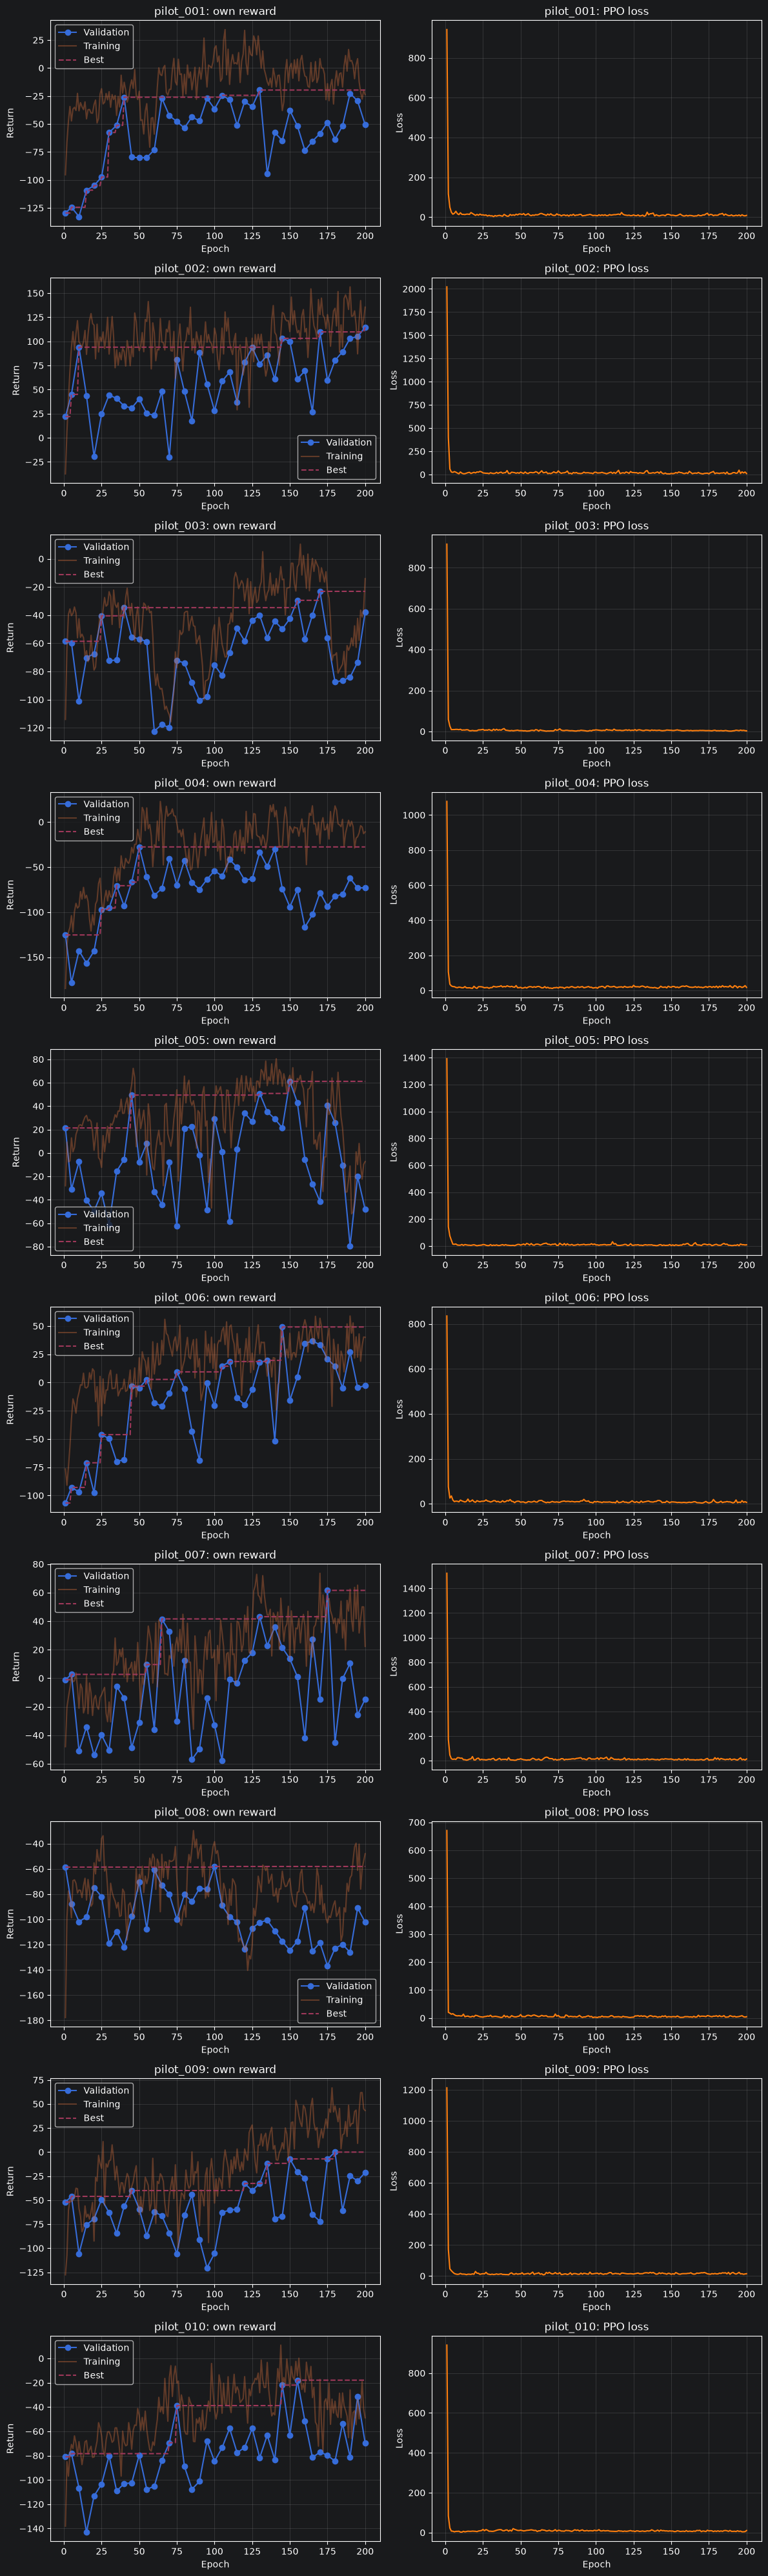

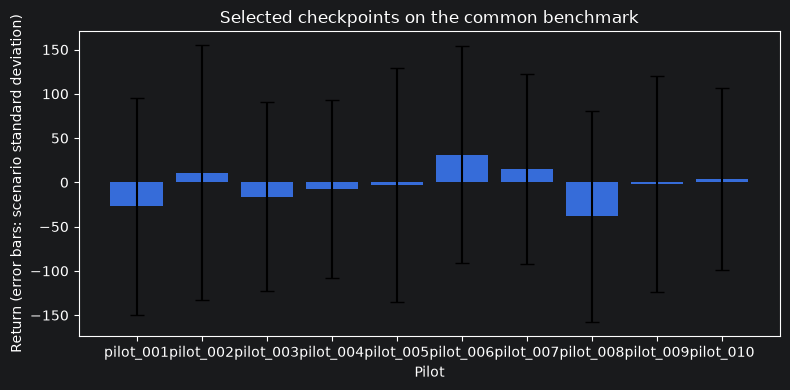

In [8]:
figure, axes = plt.subplots(len(completed), 2, figsize=(12, 4 * len(completed)), squeeze=False)
for row, pilot in enumerate(completed):
    metrics = metrics_by_pilot[pilot["pilot_id"]]
    evaluated = metrics[metrics["evaluation_performed"] == 1]
    axes[row, 0].plot(evaluated["epoch"], evaluated["mean_return"], marker="o", label="Validation")
    axes[row, 0].plot(metrics["epoch"], metrics["training_mean_return"], alpha=0.4, label="Training")
    axes[row, 0].plot(metrics["epoch"], metrics["best_return"], linestyle="--", label="Best")
    axes[row, 0].set(title=f"{pilot['pilot_id']}: own reward", xlabel="Epoch", ylabel="Return")
    axes[row, 0].legend()
    axes[row, 1].plot(metrics["epoch"], metrics["loss"], color="tab:orange")
    axes[row, 1].set(title=f"{pilot['pilot_id']}: PPO loss", xlabel="Epoch", ylabel="Loss")
    for axis in axes[row]:
        axis.grid(alpha=0.25)
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(8, 4))
axis.bar(summary["pilot_id"], summary["benchmark_return"],
         yerr=summary["benchmark_return_std"], capsize=5)
axis.set(title="Selected checkpoints on the common benchmark",
         xlabel="Pilot", ylabel="Return (error bars: scenario standard deviation)")
figure.tight_layout()
plt.show()

## Inspect the selected pilot

The replay cell saves the selected pilot's checkpoint hash and reward definition alongside
every ACMI flight. Change `BVR_PILOT_VIEW` or `SELECTED_PILOT` in that cell to inspect
another completed pilot. Open the `.txt.acmi` files in Tacview for the full flights.

Example ACMI: C:\Users\theon\Trajectory_Classification\artifacts\rl_pilot_simplified\varied_transformers\20261112T232045_249258Z\pilot_001\final_evaluation\scenario_000_seed_100067.txt.acmi
Evaluation return: 16.22


,decisions
skill,
launch,12
change_trajectory,7


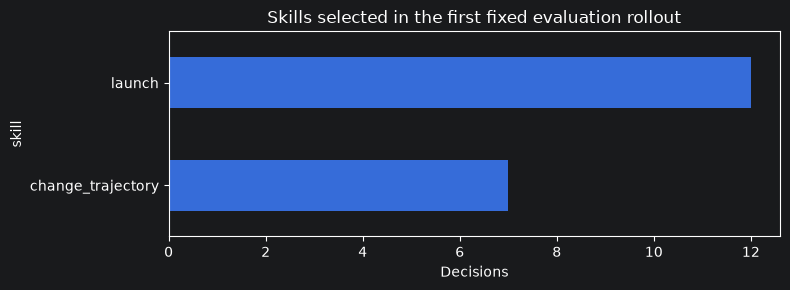

In [9]:
rollout = final_evaluation_rollouts[0]
first_evaluation = final_evaluation_manifest[0]
evaluation_return = first_evaluation["score"]
final_info = first_evaluation["final_info"]
print(f"Example ACMI: {FINAL_EVALUATION_DIR / first_evaluation['acmi']}")
selected_skills = [trained_pilot.skill_names[index] for index in rollout.skills]
skill_counts = pd.Series(selected_skills).value_counts().rename_axis("skill").rename("decisions")
print(f"Evaluation return: {evaluation_return:.2f}")
display(skill_counts.to_frame())

skill_counts.sort_values().plot.barh(figsize=(8, max(3, len(skill_counts) * 0.35)))
plt.title("Skills selected in the first fixed evaluation rollout")
plt.xlabel("Decisions")
plt.tight_layout()
plt.show()


## Next steps

- Compare the trained pilots in Tacview and on a separate held-out scenario set.
- Tune each `RewardDefinition`, or add more `PilotSpec` entries with unique IDs.
- Use `load_trained_pilot(run_directory)` to load a checkpoint after restarting Python.
- Retain `config.json`, `manifest.json`, and the checkpoint together when publishing through
  `shared/models/`. Each generated flight corpus should identify its pilot and checkpoint hash.
- Checkpoints contain inference weights; they do not resume an interrupted optimizer.